# Harmonic-weighted Gregory series: one trajectory for every $M$

For an integer $M\ge2$ put $z=1/M$, $k=M-1$ and $O_n=\sum_{m=0}^n(2m+1)^{-1}$. The paper
(Section 8, *Changing the argument*) studies
$$B(M)=\sqrt{1-z}\;{}_3F_2\!\left(\begin{matrix}\tfrac12,\tfrac12,\tfrac12\\\tfrac32,\tfrac32\end{matrix};z\right)
=\sum_{n\ge0}\frac{(-1)^nO_n}{(2n+1)k^n}.$$
The shift matrices of the ${}_3F_2(z)$ CMF are rational in $z$, so one trajectory, with the
initial point, direction and readout fixed, gives one approximation scheme for every $M$:

**CMF:** ${}_3F_2(1/M)$ · **Start:** $(\tfrac12,\tfrac12,\tfrac12;\tfrac32,\tfrac32)$ ·
**Direction:** $(2,2,2;3,3)$. We use the inverse-transpose walk and the readout
$$r_N=\frac{s_0}{s_0+4s_1+4s_2}.$$
At the start the denominator row reads $(1-z)^{-1/2}$, so $r_N\to B(M)$.

The paper's CMF theorem (under its hypothesis (H)) proves a positive exponent for every
$M\ge7165$, with $\delta\ge g(M)/\sigma(M)-1$; here $g(M)=\log(\mu_2/\mu_1)$ for the two smallest
roots of
$$\chi_z(\mu)=\mu^3-(3z+\tfrac{27}2)\mu^2+(3z^2-\tfrac{81}2z+\tfrac{729}{16})\mu-z^3,$$
and $\sigma(M)=2\log M+\log16+2\log\tfrac{27}4+8$. The inequality $g>\sigma$ fails for
$2\le M\le7164$. The two smallest members are $B(2)=\tfrac12G+\tfrac\pi8\log2$ and
$B(4)=\tfrac98L(2,\chi_{-3})$.

The target is computed through the paper's dilogarithm form
$B(M)=\tfrac{\sqrt k}2\operatorname{Im}\operatorname{Li}_2(w)$, $w=2/(1-i\sqrt k)$.
Each example prints $\delta_N$ at depth 1000; the figure at the end plots $\delta_N$ against
$N$. Run the cells in order (Python 3.11+). A finite-depth $\delta_N$ does not prove a
measure bound.

In [1]:
# @title Install dependencies (run once per environment)
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 matplotlib==3.11.2

## Setup

$(s_0,s_1,s_2)$ is the first column of the inverse-transpose walk.

In [2]:
import math
import sys

import matplotlib.pyplot as plt
import sympy as sp
from flint import acb, arb, ctx, fmpq, fmpq_poly
from ramanujantools.cmf.pfq import pFq

sys.set_int_max_str_digits(0)
DPS = 25_000  # the approximants agree with B(M) to about 20,500 digits at M = 10^6, depth 1000
DEPTHS = list(range(10, 1001, 10))
x0, x1, x2, y0, y1 = sp.symbols("x0 x1 x2 y0 y1")
half = sp.Rational(1, 2)
START = {x0: half, x1: half, x2: half, y0: 3 * half, y1: 3 * half}
TRAJECTORY = {x0: 2, x1: 2, x2: 2, y0: 3, y1: 3}
KAPPA = math.log(16) + 2 * math.log(27 / 4) + 8
results = {}


def B(M):
    """B(M) = (sqrt(k)/2) Im Li_2(w), w = 2/(1 - i sqrt(k)), k = M - 1."""
    k = arb(M - 1)
    return k.sqrt() / 2 * acb.polylog(2 / (1 - acb(0, 1) * k.sqrt()), 2).imag


def delta(approximant, value):
    """delta with |value - p/q| = q^-(1 + delta), for the reduced fraction p/q."""
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(2 * q.bit_length() + 64):  # enough bits to resolve |value - p/q|
        error = abs(value - arb(p) / q)
    return float((-1 - error.log() / arb(q).log()).mid())


def gregory_deltas(M):
    """delta_N of the trajectory at z = 1/M, for N in DEPTHS."""
    cmf = pFq(3, 2, sp.Rational(1, M)).dual()  # inverse-transpose matrices
    walks = cmf.walk(TRAJECTORY, DEPTHS, START)
    approximants = [W[0, 0] / (W[0, 0] + 4 * W[1, 0] + 4 * W[2, 0]) for W in walks]
    with ctx.workdps(DPS):
        value = B(M)
    return [delta(r, value) for r in approximants]


def proved_bound(M):
    """g(M)/sigma(M) - 1, the paper's lower bound for delta when it is positive."""
    z = fmpq(1, M)
    chi = fmpq_poly([-z**3, 3 * z**2 - fmpq(81, 2) * z + fmpq(729, 16), -(3 * z + fmpq(27, 2)), 1])
    mu1, mu2, _ = sorted(float(root.real) for root, _ in chi.complex_roots())
    return math.log(mu2 / mu1) / (2 * math.log(M) + KAPPA) - 1

## 1. $M=2$: $B(2)=\tfrac12G+\tfrac\pi8\log2$

$G$ is Catalan's constant; its irrationality, and hence that of $B(2)$, is open.

In [3]:
with ctx.workdps(60):
    print(f"B(2) - (G/2 + pi log 2 / 8) = {B(2) - (arb.const_catalan() / 2 + arb.pi() * arb(2).log() / 8)}")
deltas = gregory_deltas(2)
results["$M=2$"] = (DEPTHS, deltas)
print(f"delta at depth 1000: {deltas[-1]:.9f}")

B(2) - (G/2 + pi log 2 / 8) = [+/- 2.10e-61]
delta at depth 1000: -0.568430479


## 2. $M=4$: $B(4)=\tfrac98L(2,\chi_{-3})$

$L(2,\chi_{-3})$ is irrational by Calegari–Dimitrov–Tang; compare the dedicated
${}_4F_3(\tfrac14)$ trajectory in `l2chi3_history.ipynb`.

In [4]:
with ctx.workdps(60):
    l2chi3 = 2 / arb(3).sqrt() * acb.polylog(acb.exp_pi_i(acb(2) / 3), 2).imag
    print(f"B(4) - 9 L(2, chi_-3) / 8 = {B(4) - 9 * l2chi3 / 8}")
deltas = gregory_deltas(4)
results["$M=4$"] = (DEPTHS, deltas)
print(f"delta at depth 1000: {deltas[-1]:.9f}")

B(4) - 9 L(2, chi_-3) / 8 = [+/- 5.08e-60]
delta at depth 1000: -0.291830915


## 3. $M=7165$: the threshold of the CMF theorem

In [5]:
deltas = gregory_deltas(7165)
results["$M=7165$"] = (DEPTHS, deltas)
print(f"delta at depth 1000: {deltas[-1]:.9f}")
print(f"proved lower bound g/sigma - 1: {proved_bound(7165):.3e}")

delta at depth 1000: 0.001896132
proved lower bound g/sigma - 1: 2.756e-06


## 4. $M=10^6$

In [6]:
deltas = gregory_deltas(10**6)
results["$M=10^6$"] = (DEPTHS, deltas)
print(f"delta at depth 1000: {deltas[-1]:.9f}")
print(f"proved lower bound g/sigma - 1: {proved_bound(10**6):.9f}")

delta at depth 1000: 0.197540755
proved lower bound g/sigma - 1: 0.117266516


## The threshold $M=7165$

$g/\sigma-1$ changes sign between $M=7164$ and $M=7165$, as the paper states. This
floating-point check is not the paper's rigorous root isolation.

In [7]:
for M in (7163, 7164, 7165, 7166):
    print(f"M = {M}: g/sigma - 1 = {proved_bound(M):+.3e}")

M = 7163: g/sigma - 1 = -5.936e-06
M = 7164: g/sigma - 1 = -1.590e-06
M = 7165: g/sigma - 1 = +2.756e-06
M = 7166: g/sigma - 1 = +7.101e-06


## All values of $M$

$\delta_N$ against the walk depth $N$.

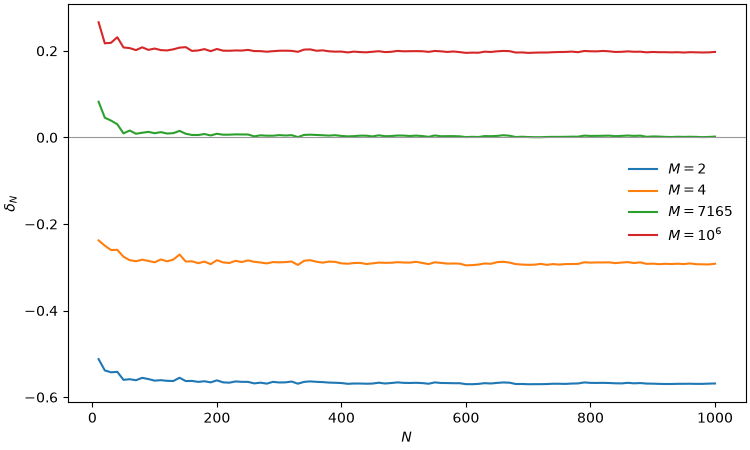

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(depths, values, label=name)
ax.axhline(0, color="0.6", linewidth=0.8)
ax.set(xlabel="$N$", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()

## Overview

| Irrationality of $B(M)$ | Range | Notebook coverage |
|:--|:--|:--|
| CMF trajectory above, under hypothesis (H) | $M\ge7165$ | CMF above |
| Unconditional, same approximants | $M\ge8692475$ | same CMF |
| Polylogarithm criterion (Kawashima, preprint) | $M>2^{26}e^{16}\approx5.96\cdot10^{14}$ | reference only |
| Fischler–Rivoal, explicit | $M-1>2^{2412}$ | reference only |

At $M=7165$ and $M=10^6$ the finite-depth $\delta_N$ exceeds the proved bound $g/\sigma-1$:
the proof bounds the denominators by an explicit integer normalization, while $\delta_N$
uses the reduced ones.